In [1]:
import pandas as pd 
import numpy as np 

In [2]:
df = pd.read_csv(r"C:\Users\Nidho\Downloads\Traning Dataset-001\Traning Dataset\loan_approval_dataset.csv")
print(df.head(10))
df.info()

   loan_id   no_of_dependents      education  self_employed   income_annum  \
0        1                  2       Graduate             No      9600000.0   
1        2                  0   Not Graduate            Yes      4100000.0   
2        3                  3       Graduate             No      9100000.0   
3        4                  3       Graduate             No      8200000.0   
4        5                  5   Not Graduate            Yes      9800000.0   
5        6                  0       Graduate            Yes      4800000.0   
6        7                  5       Graduate             No      8700000.0   
7        8                  2       Graduate            Yes      5700000.0   
8        9                  0       Graduate            Yes       800000.0   
9       10                  5   Not Graduate             No      1100000.0   

    loan_amount   loan_term   cibil_score   residential_assets_value  \
0    29900000.0          12           778                  2400000.0 

In [3]:
df.isna().sum()

loan_id                      0
 no_of_dependents            0
 education                   3
 self_employed               0
 income_annum                3
 loan_amount                 4
 loan_term                   0
 cibil_score                 0
 residential_assets_value    5
 commercial_assets_value     4
 luxury_assets_value         1
 bank_asset_value            3
 loan_status                 1
dtype: int64

In [4]:
df = df.dropna()

In [5]:
df.isna().sum()

loan_id                      0
 no_of_dependents            0
 education                   0
 self_employed               0
 income_annum                0
 loan_amount                 0
 loan_term                   0
 cibil_score                 0
 residential_assets_value    0
 commercial_assets_value     0
 luxury_assets_value         0
 bank_asset_value            0
 loan_status                 0
dtype: int64

In [6]:
print(df.duplicated().sum())

0


In [7]:
df.columns = df.columns.str.strip()
df.info()

<class 'pandas.DataFrame'>
Index: 4245 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   loan_id                   4245 non-null   int64  
 1   no_of_dependents          4245 non-null   int64  
 2   education                 4245 non-null   str    
 3   self_employed             4245 non-null   str    
 4   income_annum              4245 non-null   float64
 5   loan_amount               4245 non-null   float64
 6   loan_term                 4245 non-null   int64  
 7   cibil_score               4245 non-null   int64  
 8   residential_assets_value  4245 non-null   float64
 9   commercial_assets_value   4245 non-null   float64
 10  luxury_assets_value       4245 non-null   float64
 11  bank_asset_value          4245 non-null   float64
 12  loan_status               4245 non-null   str    
dtypes: float64(6), int64(4), str(3)
memory usage: 464.3 KB


In [8]:
cat_cols = ["education", "self_employed", "loan_status"]

for col in cat_cols:
    print(col)
    print(df[col].value_counts(dropna=False))
    print()

education
education
Graduate        2135
Not Graduate    2110
Name: count, dtype: int64

self_employed
self_employed
Yes    2139
No     2106
Name: count, dtype: int64

loan_status
loan_status
Approved    2640
Rejected    1605
Name: count, dtype: int64



In [9]:
for col in cat_cols:
    df[col] = df[col].astype("string").str.strip()

print(df["education"].value_counts())
print(df["self_employed"].value_counts())
print(df["loan_status"].value_counts())

education
Graduate        2135
Not Graduate    2110
Name: count, dtype: Int64
self_employed
Yes    2139
No     2106
Name: count, dtype: Int64
loan_status
Approved    2640
Rejected    1605
Name: count, dtype: Int64


In [10]:
num_cols = [
    "no_of_dependents",
    "income_annum",
    "loan_amount",
    "loan_term",
    "cibil_score",
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value"
]
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    print(col, "Potential outliers:", count)

no_of_dependents Potential outliers: 0
income_annum Potential outliers: 0
loan_amount Potential outliers: 0
loan_term Potential outliers: 0
cibil_score Potential outliers: 0
residential_assets_value Potential outliers: 52
commercial_assets_value Potential outliers: 37
luxury_assets_value Potential outliers: 0
bank_asset_value Potential outliers: 8


In [11]:
X = df.drop(columns=["loan_id", "loan_status"])
y = df["loan_status"]

print(X.head())
print(y.value_counts())

   no_of_dependents     education self_employed  income_annum  loan_amount  \
0                 2      Graduate            No     9600000.0   29900000.0   
1                 0  Not Graduate           Yes     4100000.0   12200000.0   
2                 3      Graduate            No     9100000.0   29700000.0   
3                 3      Graduate            No     8200000.0   30700000.0   
4                 5  Not Graduate           Yes     9800000.0   24200000.0   

   loan_term  cibil_score  residential_assets_value  commercial_assets_value  \
0         12          778                 2400000.0               17600000.0   
1          8          417                 2700000.0                2200000.0   
2         20          506                 7100000.0                4500000.0   
3          8          467                18200000.0                3300000.0   
4         20          382                12400000.0                8200000.0   

   luxury_assets_value  bank_asset_value  
0      

In [12]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print(X_train.shape)
print(X_test.shape)

(3396, 11)
(849, 11)


In [13]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

cat_features = ["education", "self_employed"]
num_features = [col for col in X.columns if col not in cat_features]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
        ("num", "passthrough", num_features)
    ]
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print(X_train_encoded.shape)
print(X_test_encoded.shape)

(3396, 13)
(849, 13)


In [14]:
print("Training rows:", X_train_encoded.shape[0])
print("Testing rows:", X_test_encoded.shape[0])

print("Training target distribution:")
print(y_train.value_counts(normalize=True))

print("Testing target distribution:")
print(y_test.value_counts(normalize=True))

Training rows: 3396
Testing rows: 849
Training target distribution:
loan_status
Approved    0.621908
Rejected    0.378092
Name: proportion, dtype: Float64
Testing target distribution:
loan_status
Approved    0.621908
Rejected    0.378092
Name: proportion, dtype: Float64


In [15]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_encoded, y_train)

print("Model trained successfully!")

Model trained successfully!


In [16]:
y_pred = model.predict(X_test_encoded)

print("Actual values:")
print(y_test.head(10).tolist())

print("Predicted values:")
print(y_pred[:10])

Actual values:
['Approved', 'Approved', 'Rejected', 'Rejected', 'Rejected', 'Approved', 'Approved', 'Rejected', 'Approved', 'Approved']
Predicted values:
['Approved' 'Approved' 'Rejected' 'Approved' 'Rejected' 'Rejected'
 'Approved' 'Rejected' 'Approved' 'Approved']


In [17]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 81.04 %


In [18]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    Approved       0.80      0.92      0.86       528
    Rejected       0.83      0.63      0.72       321

    accuracy                           0.81       849
   macro avg       0.81      0.78      0.79       849
weighted avg       0.81      0.81      0.80       849



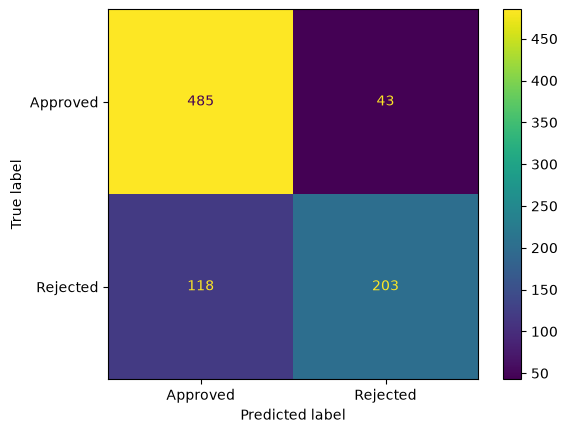

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

display.plot()
plt.show()